# Car insurance claim frequency - notebook

**Goal:** predict how many claims a motor insurance policy will file per year, so an
insurer or broker can price the policy and spot risky profiles before quoting.

Contents:
1. Data loading and cleaning
2. Target analysis (claims, exposure, frequency)
3. EDA: how each feature relates to claim frequency
4. Feature importance
5. Validation setup and metrics
6. Models: baseline, Poisson GLM (linear), Random Forest, XGBoost - each tuned
7. Final comparison on the test set
8. Save the selected hyper-parameters for `train.py`

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

from common import (CATEGORICAL, NUMERICAL, evaluate, load_data, make_glm,
                    prepare_features, split, tree_preprocessor)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Data loading and cleaning

Dataset: **freMTPL2freq** - French motor third-party liability insurance, 678,013 policies
observed during one year (public on [OpenML, id 41214](https://www.openml.org/d/41214)).
A compressed copy is in `data/`; `download_data.py` downloads it again.

| Column | Meaning |
|---|---|
| IDpol | Policy id |
| ClaimNb | Number of claims during the exposure period (**target, counts**) |
| Exposure | Fraction of the year the policy was active (0-1) |
| Area | Density class of the city (A rural ... F urban) |
| VehPower | Power class of the car |
| VehAge | Car age (years) |
| DrivAge | Driver age (years) |
| BonusMalus | Bonus-malus level: 50 = best record, >100 = penalised for past claims |
| VehBrand | Anonymised brand (B1-B14) |
| VehGas | Regular / Diesel |
| Density | Inhabitants per km2 where the driver lives |
| Region | French region (R11 ... R94) |

In [2]:
raw = pd.read_csv("data/freMTPL2freq.csv.gz")
print(raw.shape)
raw.head()

(678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1,1,0.1000,D,5,0,55,50,B12,Regular,1217,R82
1,3,1,0.7700,D,5,0,55,50,B12,Regular,1217,R82
2,5,1,0.7500,B,6,2,52,50,B12,Diesel,54,R22
3,10,1,0.0900,B,7,0,46,50,B12,Diesel,76,R72
4,11,1,0.8400,B,7,0,46,50,B12,Diesel,76,R72


In [3]:
print("Missing values per column:")
print(raw.isna().sum().to_string())
print("\nDuplicated policy ids:", raw["IDpol"].duplicated().sum())
raw.dtypes

Missing values per column:
IDpol         0
ClaimNb       0
Exposure      0
Area          0
VehPower      0
VehAge        0
DrivAge       0
BonusMalus    0
VehBrand      0
VehGas        0
Density       0
Region        0

Duplicated policy ids: 0


IDpol           int64
ClaimNb         int64
Exposure      float64
Area              str
VehPower        int64
VehAge          int64
DrivAge         int64
BonusMalus      int64
VehBrand          str
VehGas            str
Density         int64
Region            str
dtype: object

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0000,2621856.9211,1641782.7527,1.0000,1157951.0000,2272152.0000,4046274.0000,6114330.0000
ClaimNb,678013.0000,0.0532,0.2401,0.0000,0.0000,0.0000,0.0000,16.0000
Exposure,678013.0000,0.5288,0.3644,0.0027,0.1800,0.4900,0.9900,2.0100
VehPower,678013.0000,6.4546,2.0509,4.0000,5.0000,6.0000,7.0000,15.0000
VehAge,678013.0000,7.0443,5.6662,0.0000,2.0000,6.0000,11.0000,100.0000
DrivAge,678013.0000,45.4991,14.1374,18.0000,34.0000,44.0000,55.0000,100.0000
BonusMalus,678013.0000,59.7615,15.6367,50.0000,50.0000,50.0000,64.0000,230.0000
Density,678013.0000,1792.4224,3958.6466,1.0000,92.0000,393.0000,1658.0000,27000.0000


Observations about ranges:
- **No missing values** and no duplicated policies.
- `Exposure` goes up to 2.01, but a policy-year cannot exceed 1 -> clip to 1 (1,224 rows).
- `ClaimNb` has a few extreme values (up to 16 claims in a few months). 9 policies have 5+ claims;
  they look like data errors and would dominate a count model -> cap at 4.
- `VehAge` (max 100), `DrivAge` (max 100), `BonusMalus` (max 230) and `VehPower` have long tails with
  almost no exposure -> capped in `prepare_features` (20, 90, 150, 12).
- `Density` spans 1 to 27,000 -> very skewed, we use `log(Density)`.

In [5]:
print("ClaimNb counts:", raw["ClaimNb"].value_counts().sort_index().to_dict())
print("Exposure > 1:", (raw["Exposure"] > 1).sum())
for col, cap in {"VehAge": 20, "DrivAge": 90, "BonusMalus": 150, "VehPower": 12}.items():
    print(f"{col} > {cap}: {(raw[col] > cap).sum()} rows")

ClaimNb counts: {0: 643953, 1: 32178, 2: 1784, 3: 82, 4: 7, 5: 2, 6: 1, 8: 1, 9: 1, 11: 3, 16: 1}
Exposure > 1: 1224
VehAge > 20: 8322 rows
DrivAge > 90: 401 rows
BonusMalus > 150: 209 rows
VehPower > 12: 8505 rows


In [6]:
df = load_data()  # applies the clipping above and adds Frequency = ClaimNb / Exposure
print(df.shape)
df[["ClaimNb", "Exposure", "Frequency"]].describe().T

(678013, 13)


,count,mean,std,min,25%,50%,75%,max
ClaimNb,678013.0000,0.0532,0.2380,0.0000,0.0000,0.0000,0.0000,4.0000
Exposure,678013.0000,0.5285,0.3641,0.0027,0.1800,0.4900,0.9900,1.0000
Frequency,678013.0000,0.2635,4.5856,0.0000,0.0000,0.0000,0.0000,732.0000


## 2. Target analysis

The quantity an insurer prices is the **claim frequency** = claims per policy-year.
Policies are observed for different periods, so every statistic below is **weighted by exposure**
(a policy seen for 1 month counts 1/12 of a policy seen all year).

Portfolio claim frequency: 0.1006 claims per policy-year
Policies with at least one claim: 5.02%


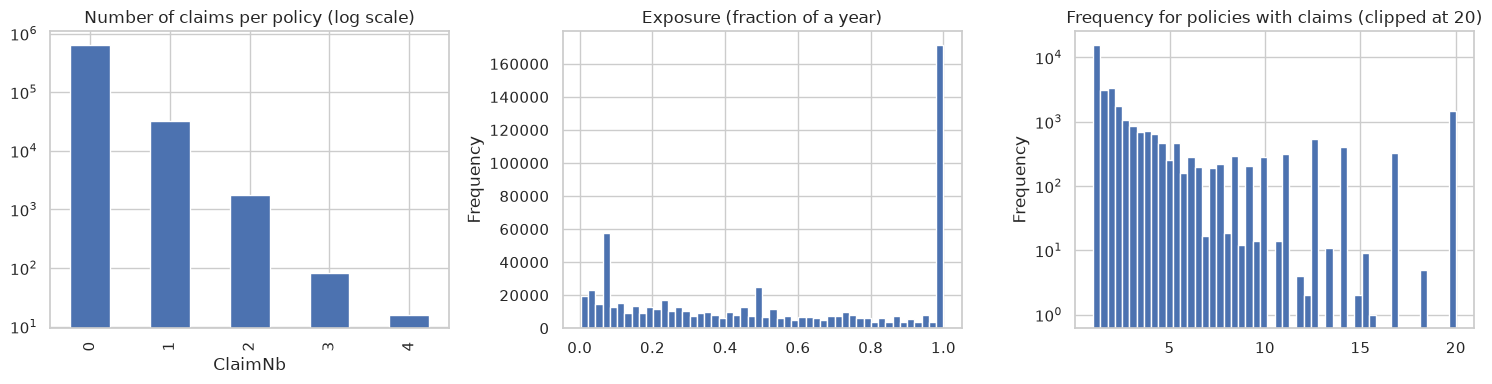

In [7]:
portfolio_freq = df["ClaimNb"].sum() / df["Exposure"].sum()
print(f"Portfolio claim frequency: {portfolio_freq:.4f} claims per policy-year")
print(f"Policies with at least one claim: {(df['ClaimNb'] > 0).mean():.2%}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["ClaimNb"].value_counts().sort_index().plot.bar(ax=axes[0], logy=True)
axes[0].set_title("Number of claims per policy (log scale)")
df["Exposure"].plot.hist(bins=50, ax=axes[1])
axes[1].set_title("Exposure (fraction of a year)")
df.loc[df["Frequency"] > 0, "Frequency"].clip(upper=20).plot.hist(bins=50, ax=axes[2], logy=True)
axes[2].set_title("Frequency for policies with claims (clipped at 20)")
plt.tight_layout()
plt.show()

- 95% of the policies have **zero claims**; the target is a highly skewed count with mean 0.10.
- That rules out plain regression with squared error: the right loss is the **Poisson deviance**,
  with the observed frequency as target and the exposure as sample weight. That is the standard
  actuarial approach and all models below use it.
- Many policies have a short exposure, so their observed frequency is very noisy (1 claim in
  0.1 years = frequency 10). The weighting handles this.

## 3. EDA: claim frequency by feature

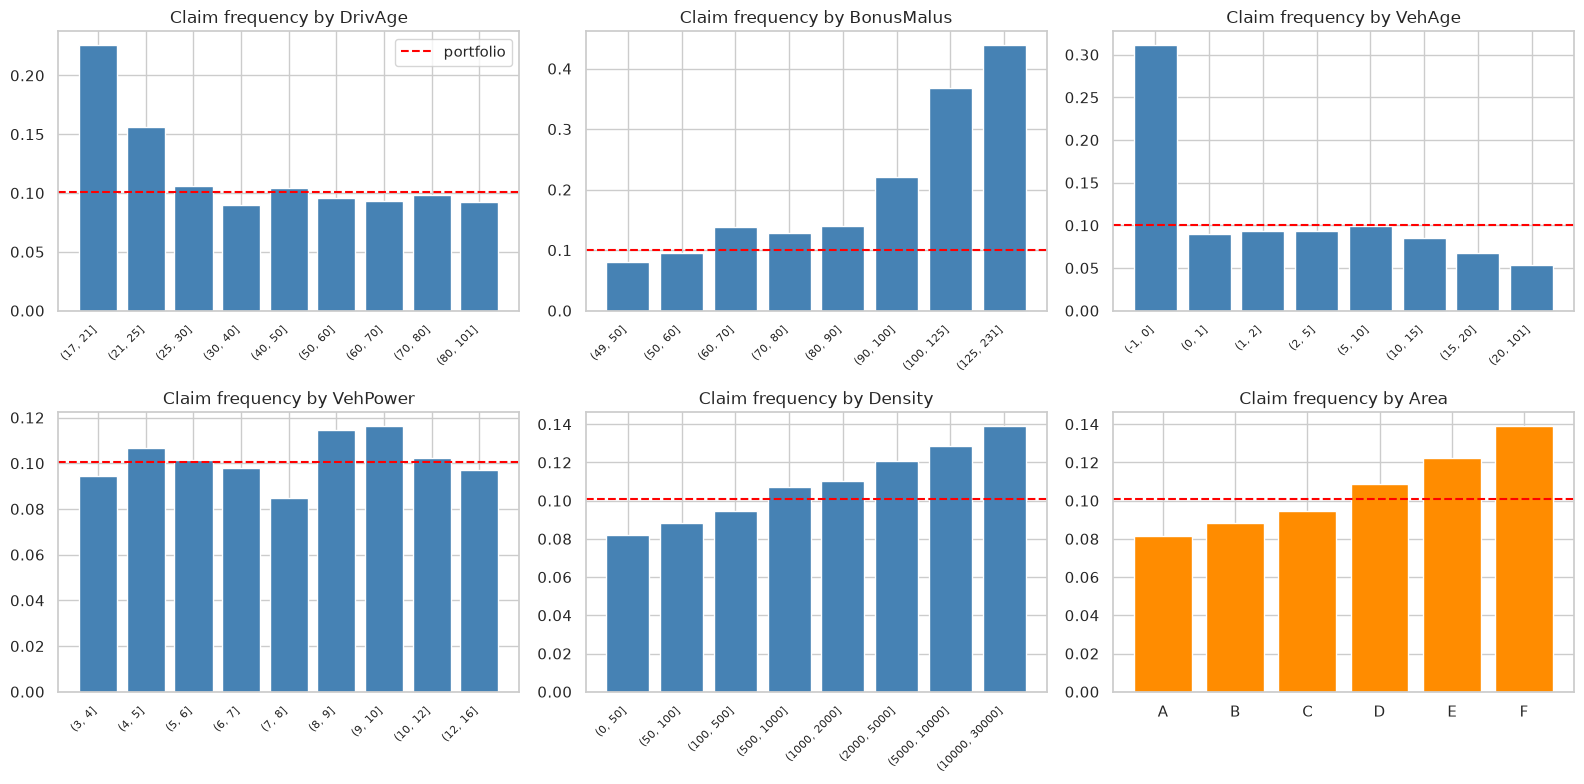

In [8]:
def freq_by(data, col, bins=None):
    key = pd.cut(data[col], bins) if bins is not None else data[col]
    g = data.groupby(key, observed=True).agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
    g["frequency"] = g["claims"] / g["exposure"]
    g["exposure_share"] = g["exposure"] / g["exposure"].sum()
    return g

numeric_bins = {
    "DrivAge": [17, 21, 25, 30, 40, 50, 60, 70, 80, 101],
    "BonusMalus": [49, 50, 60, 70, 80, 90, 100, 125, 231],
    "VehAge": [-1, 0, 1, 2, 5, 10, 15, 20, 101],
    "VehPower": [3, 4, 5, 6, 7, 8, 9, 10, 12, 16],
    "Density": [0, 50, 100, 500, 1000, 2000, 5000, 10000, 30000],
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (col, bins) in zip(axes.flat, numeric_bins.items()):
    g = freq_by(df, col, bins)
    ax.bar(range(len(g)), g["frequency"], color="steelblue")
    ax.axhline(portfolio_freq, color="red", ls="--", label="portfolio")
    ax.set_xticks(range(len(g)), [str(i) for i in g.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(f"Claim frequency by {col}")
axes.flat[0].legend()
g = freq_by(df, "Area")
axes.flat[5].bar(g.index.astype(str), g["frequency"], color="darkorange")
axes.flat[5].axhline(portfolio_freq, color="red", ls="--")
axes.flat[5].set_title("Claim frequency by Area")
plt.tight_layout()
plt.show()

In [9]:
freq_by(df, "DrivAge", numeric_bins["DrivAge"])

,claims,exposure,frequency,exposure_share
DrivAge,,,,
"(17, 21]",996,4404.4540,0.2261,0.0123
"(21, 25]",1845,11822.7393,0.1561,0.0330
"(25, 30]",3093,29167.2138,0.1060,0.0814
"(30, 40]",7522,83897.5190,0.0897,0.2341
"(40, 50]",9165,88099.9802,0.1040,0.2458
"(50, 60]",7254,75700.4160,0.0958,0.2112
"(60, 70]",3558,38321.1785,0.0928,0.1069
"(70, 80]",2188,22237.4131,0.0984,0.0621
"(80, 101]",435,4709.1915,0.0924,0.0131


In [10]:
freq_by(df, "BonusMalus", numeric_bins["BonusMalus"])

,claims,exposure,frequency,exposure_share
BonusMalus,,,,
"(49, 50]",18010,225152.6509,0.0800,0.6283
"(50, 60]",4553,47958.4670,0.0949,0.1338
"(60, 70]",3671,26484.0835,0.1386,0.0739
"(70, 80]",3386,26555.7033,0.1275,0.0741
"(80, 90]",2130,15243.4295,0.1397,0.0425
"(90, 100]",2964,13395.0423,0.2213,0.0374
"(100, 125]",1178,3197.6761,0.3684,0.0089
"(125, 231]",164,373.0529,0.4396,0.0010


Main patterns (portfolio average = 0.10 claims per policy-year):
- **BonusMalus** is the strongest signal: the best level (50, 63% of exposure) is 20% below average,
  and frequency rises steadily - drivers above 100 (penalised for past claims) file **3.7-4.4x** the average.
- **Driver age**: drivers aged 18-21 file **2.2x** the average and 21-25 file 1.6x; from 30 on the
  frequency is roughly flat. A linear term can't capture this -> splines in the GLM.
- **Vehicle age**: brand-new cars (age 0) file **3.1x** the average, then the frequency falls slowly
  with age (cars over 15 years: ~0.6x).
- **Density / Area**: frequency rises steadily from rural (Area A, 0.8x) to dense urban areas (Area F, 1.4x).
- **Vehicle power**: weak effect.

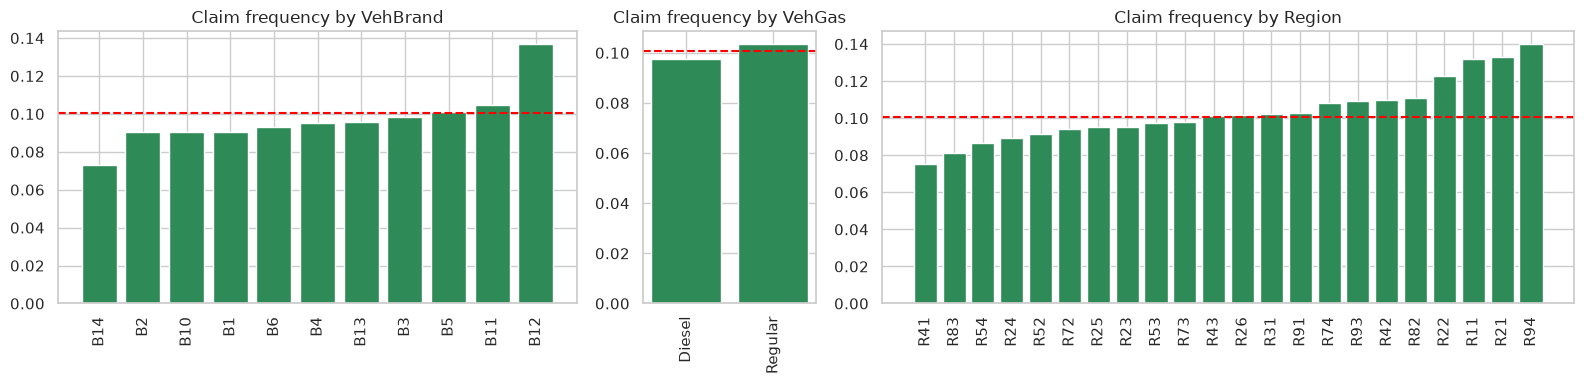

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [3, 1, 4]})
for ax, col in zip(axes, ["VehBrand", "VehGas", "Region"]):
    g = freq_by(df, col).sort_values("frequency")
    ax.bar(g.index.astype(str), g["frequency"], color="seagreen")
    ax.axhline(portfolio_freq, color="red", ls="--")
    ax.set_title(f"Claim frequency by {col}")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

In [12]:
freq_by(df, "Region").sort_values("exposure", ascending=False).head(10)

,claims,exposure,frequency,exposure_share
Region,,,,
R24,9197,102706.4434,0.0895,0.2866
R82,5032,45332.5873,0.1110,0.1265
R93,3906,35748.9810,0.1093,0.0998
R11,3978,30198.1320,0.1317,0.0843
R53,2702,27752.7937,0.0974,0.0774
R52,2010,21930.3212,0.0917,0.0612
R91,1509,14710.6242,0.1026,0.0410
R72,1348,14316.1667,0.0942,0.0399
R31,1176,11488.0743,0.1024,0.0321


- **Brand**: B12 stands out with 1.36x the average frequency. It is linked to new cars: 64% of the
  age-0 vehicles are B12 (vs 21% of older cars), and new cars have the highest frequency.
- **Gas**: Diesel (0.97x) and Regular (1.03x) are close.
- **Region**: moderate differences; R11 (Paris region) is 1.3x the average, R24 (largest region) 0.9x.

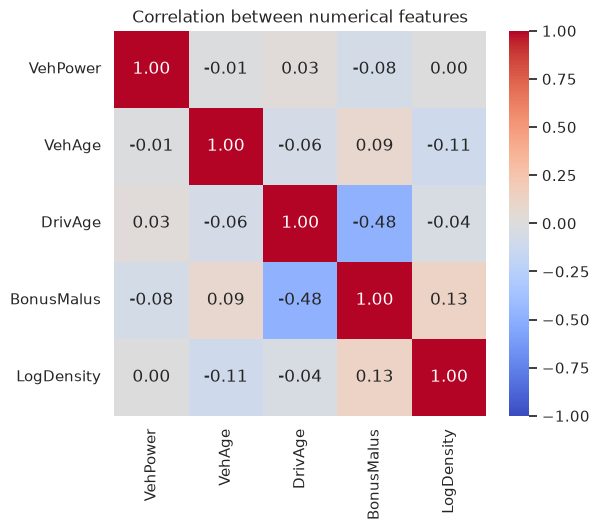

In [13]:
num = prepare_features(df)[NUMERICAL]
plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numerical features")
plt.show()

Correlations are low except `BonusMalus` vs `DrivAge` (-0.48: young drivers start with a worse
level) and `LogDensity` (strongly tied to `Area`, which is a binned version of density).
Both kept: tree models are robust to it and the GLM is regularised.

## 4. Feature importance

Univariate check: for each feature, fit a one-feature Poisson GLM and measure the **share of
Poisson deviance it explains (D2)** on the training data. It is the count-data analogue of
mutual information / single-feature AUC used in the course.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import OneHotEncoder, SplineTransformer
from common import d2_score

train, val, test = split(df)
X_train = prepare_features(train)
rows = []
for col in CATEGORICAL + NUMERICAL:
    enc = (OneHotEncoder(handle_unknown="ignore") if col in CATEGORICAL
           else SplineTransformer(n_knots=5))
    m = Pipeline([("pre", ColumnTransformer([("f", enc, [col])])),
                  ("glm", PoissonRegressor(alpha=1e-4, solver="newton-cholesky"))])
    m.fit(X_train, train["Frequency"], glm__sample_weight=train["Exposure"])
    rows.append((col, d2_score(train["Frequency"], m.predict(X_train), train["Exposure"])))
univariate = pd.DataFrame(rows, columns=["feature", "d2"]).sort_values("d2", ascending=False)
univariate

,feature,d2
7,BonusMalus,0.0204
5,VehAge,0.0185
1,VehBrand,0.0048
8,LogDensity,0.0040
0,Area,0.0038
6,DrivAge,0.0038
3,Region,0.0034
4,VehPower,0.0006
2,VehGas,0.0002


`BonusMalus` explains the most deviance, followed closely by `VehAge` (driven by the brand-new cars).
Brand, density/area, driver age and region follow; power and gas add very little on their own.
Permutation importance of the final model is computed in section 7.

## 5. Validation setup and metrics

- Split **60% train / 20% validation / 20% test** (`common.split`, seed 42). Hyper-parameters are chosen
  on validation; the test set is used once at the end.
- Target `Frequency`, weight `Exposure`.
- Metrics (all exposure-weighted, in `common.py`):
  - **Mean Poisson deviance** - main metric for tuning (lower is better).
  - **D2** - share of deviance explained vs. predicting the portfolio mean (higher is better).
  - **Gini** (normalised, ordered Lorenz curve) - how well the model ranks safe vs risky policies,
    which is what matters for pricing (higher is better).

Note: on claim counts, D2 values of 5-10% are normal - most claims are random events. The
interesting part is how well the model separates risk (Gini).

In [15]:
X_val = prepare_features(val)
y_train, w_train = train["Frequency"], train["Exposure"]
y_val, w_val = val["Frequency"], val["Exposure"]
print(len(train), len(val), len(test))

results = {}
mean_freq = np.average(y_train, weights=w_train)
results["Baseline (portfolio mean)"] = evaluate(y_val, np.full(len(val), mean_freq), w_val)
results

406807 135603 135603


{'Baseline (portfolio mean)': {'poisson_deviance': 0.62612,
  'd2': -3e-05,
  'gini': -0.00387}}

## 6. Models

### 6.1 Poisson GLM (linear model)

The traditional actuarial model: `log(frequency) = linear combination of features`.
One-hot for categories, cubic **splines** for numerical features (so the U-shape of driver age fits).
Tuned: L2 regularisation `alpha`.

In [16]:
glm_scores = {}
for alpha in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    glm = make_glm(alpha).fit(X_train, y_train, model__sample_weight=w_train)
    glm_scores[alpha] = evaluate(y_val, glm.predict(X_val), w_val)
glm_table = pd.DataFrame(glm_scores).T.rename_axis("alpha")
glm_table

,poisson_deviance,d2,gini
alpha,,,
0.0000,0.5943,0.0508,0.2903
0.0000,0.5943,0.0508,0.2903
0.0001,0.5943,0.0508,0.2906
0.0010,0.5942,0.0509,0.2917
0.0100,0.5958,0.0485,0.2894
0.1000,0.6020,0.0385,0.2742


In [17]:
best_alpha = glm_table["poisson_deviance"].idxmin()
glm = make_glm(best_alpha).fit(X_train, y_train, model__sample_weight=w_train)
results[f"Poisson GLM (alpha={best_alpha:g})"] = evaluate(y_val, glm.predict(X_val), w_val)
print("best alpha:", best_alpha)

best alpha: 0.001


### 6.2 Random Forest (tree-based)

`criterion="poisson"` so splits minimise Poisson deviance. Each tree sees 50% of the rows
(`max_samples`) to keep training time reasonable on 400k rows. Tuned: `max_depth`, `min_samples_leaf`.

In [18]:
pre = tree_preprocessor().fit(X_train)
A_train, A_val = pre.transform(X_train), pre.transform(X_val)

rf_scores = {}
for depth in [8, 12, None]:
    for leaf in [200, 500, 1000]:
        rf = RandomForestRegressor(n_estimators=60, criterion="poisson", max_depth=depth,
                                   min_samples_leaf=leaf, max_samples=0.5, n_jobs=-1, random_state=42)
        rf.fit(A_train, y_train, sample_weight=w_train)
        rf_scores[(str(depth), leaf)] = evaluate(y_val, rf.predict(A_val), w_val)
rf_table = pd.DataFrame(rf_scores).T.rename_axis(["max_depth", "min_samples_leaf"])
rf_table.sort_values("poisson_deviance")

poisson_deviance     d2   gini
max_depth min_samples_leaf                                
None      200                         0.5762 0.0796 0.3439
12        200                         0.5765 0.0792 0.3416
None      500                         0.5772 0.0782 0.3408
12        500                         0.5774 0.0778 0.3393
8         200                         0.5777 0.0773 0.3316
          500                         0.5785 0.0761 0.3310
None      1000                        0.5794 0.0746 0.3345
12        1000                        0.5795 0.0744 0.3332
8         1000                        0.5803 0.0731 0.3266

In [19]:
rf_best = rf_table["poisson_deviance"].idxmin()
results[f"Random Forest (depth={rf_best[0]}, leaf={rf_best[1]})"] = rf_table.loc[rf_best].to_dict()
rf_depth = None if rf_best[0] == "None" else int(rf_best[0])
rf_leaf = int(rf_best[1])
rf_best

('None', np.int64(200))

### 6.3 XGBoost (gradient boosting)

`objective="count:poisson"`. Tuned `max_depth` and `min_child_weight` with `learning_rate=0.1`;
the number of trees is picked with **early stopping** on validation. Then the best combination is
refit with a smaller learning rate (0.05), which usually adds a little accuracy.

In [20]:
def fit_xgb(params, A_tr, y_tr, w_tr):
    model = xgb.XGBRegressor(objective="count:poisson", n_estimators=3000, early_stopping_rounds=50,
                             eval_metric="poisson-nloglik", subsample=0.8, colsample_bytree=0.8,
                             tree_method="hist", n_jobs=-1, random_state=42, **params)
    model.fit(A_tr, y_tr, sample_weight=w_tr, eval_set=[(A_val, y_val)],
              sample_weight_eval_set=[w_val], verbose=False)
    return model

xgb_scores = {}
for depth in [3, 4, 6, 8]:
    for mcw in [10, 50, 200]:
        m = fit_xgb({"max_depth": depth, "min_child_weight": mcw, "learning_rate": 0.1},
                    A_train, y_train, w_train)
        xgb_scores[(depth, mcw)] = {**evaluate(y_val, m.predict(A_val), w_val), "trees": m.best_iteration + 1}
xgb_table = pd.DataFrame(xgb_scores).T.rename_axis(["max_depth", "min_child_weight"])
xgb_table.sort_values("poisson_deviance")

poisson_deviance     d2   gini     trees
max_depth min_child_weight                                          
8         10                          0.5712 0.0876 0.3588  238.0000
          50                          0.5719 0.0866 0.3553  234.0000
6         10                          0.5721 0.0863 0.3561  390.0000
          50                          0.5725 0.0857 0.3547  293.0000
          200                         0.5730 0.0848 0.3536  624.0000
8         200                         0.5731 0.0847 0.3535  259.0000
4         10                          0.5731 0.0846 0.3544  718.0000
          50                          0.5732 0.0844 0.3532  842.0000
          200                         0.5738 0.0835 0.3513  846.0000
3         50                          0.5746 0.0823 0.3496 1151.0000
          10                          0.5746 0.0822 0.3507 1150.0000
          200                         0.5750 0.0816 0.3481 1439.0000

In [21]:
depth, mcw = xgb_table["poisson_deviance"].idxmin()
xgb_model = fit_xgb({"max_depth": int(depth), "min_child_weight": int(mcw), "learning_rate": 0.05},
                    A_train, y_train, w_train)
xgb_trees = xgb_model.best_iteration + 1
results[f"XGBoost (depth={depth}, mcw={mcw}, lr=0.05)"] = evaluate(y_val, xgb_model.predict(A_val), w_val)
print("trees with lr=0.05:", xgb_trees)

trees with lr=0.05: 430


### Model comparison (validation set)

In [22]:
comparison = pd.DataFrame(results).T
comparison.sort_values("poisson_deviance")

,poisson_deviance,d2,gini
"XGBoost (depth=8, mcw=10, lr=0.05)",0.5713,0.0876,0.3574
"Random Forest (depth=None, leaf=200)",0.5762,0.0796,0.3439
Poisson GLM (alpha=0.001),0.5942,0.0509,0.2917
Baseline (portfolio mean),0.6261,-0.0000,-0.0039


## 7. Final evaluation on the test set

Every tuned model is refit on train + validation and scored once on the untouched test set.

In [23]:
full = pd.concat([train, val], ignore_index=True)
X_full, X_test = prepare_features(full), prepare_features(test)
y_full, w_full = full["Frequency"], full["Exposure"]
y_test, w_test = test["Frequency"], test["Exposure"]

final_glm = make_glm(best_alpha).fit(X_full, y_full, model__sample_weight=w_full)
final_rf = Pipeline([("pre", tree_preprocessor()), ("model", RandomForestRegressor(
    n_estimators=200, criterion="poisson", max_depth=rf_depth, min_samples_leaf=rf_leaf,
    max_samples=0.5, n_jobs=-1, random_state=42))]).fit(X_full, y_full, model__sample_weight=w_full)
xgb_params = {"max_depth": int(depth), "min_child_weight": int(mcw), "learning_rate": 0.05,
              "subsample": 0.8, "colsample_bytree": 0.8, "n_estimators": int(xgb_trees)}
final_xgb = Pipeline([("pre", tree_preprocessor()), ("model", xgb.XGBRegressor(
    objective="count:poisson", tree_method="hist", n_jobs=-1, random_state=42, **xgb_params))]
).fit(X_full, y_full, model__sample_weight=w_full)

preds = {"Baseline": np.full(len(test), np.average(y_full, weights=w_full)),
         "Poisson GLM": final_glm.predict(X_test),
         "Random Forest": final_rf.predict(X_test),
         "XGBoost": final_xgb.predict(X_test)}
test_table = pd.DataFrame({k: evaluate(y_test, p, w_test) for k, p in preds.items()}).T
test_table

,poisson_deviance,d2,gini
Baseline,0.6274,-0.0000,0.0150
Poisson GLM,0.5971,0.0482,0.2937
Random Forest,0.5795,0.0764,0.3407
XGBoost,0.5756,0.0825,0.3519


**Lorenz curve** - policies sorted from lowest to highest predicted risk: a good model concentrates
the claims in the last (riskiest) policies, so its curve sits further below the diagonal.

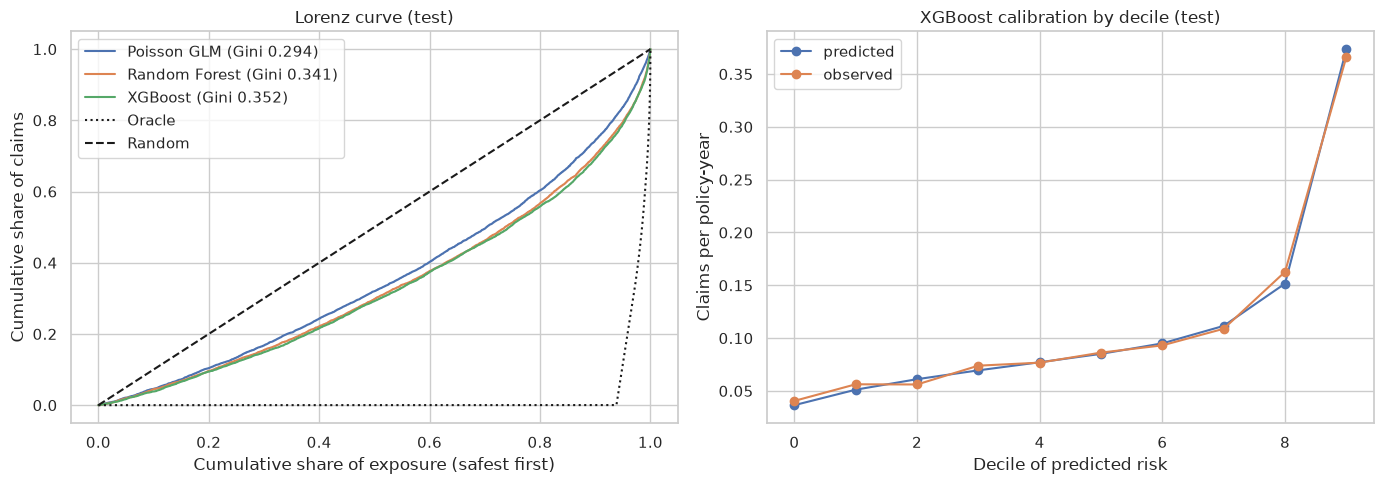

,predicted,observed
decile,,
0,0.0365,0.0406
1,0.0512,0.0563
2,0.0611,0.0561
3,0.0695,0.0739
4,0.0772,0.0768
5,0.0851,0.0863
6,0.0951,0.0932
7,0.1116,0.1089
8,0.1517,0.1628


In [24]:
def lorenz(y, pred, w):
    order = np.argsort(pred)
    cw = np.concatenate([[0], np.cumsum(np.asarray(w)[order]) / np.sum(w)])
    cc = np.concatenate([[0], np.cumsum((np.asarray(y) * np.asarray(w))[order]) / np.sum(np.asarray(y) * np.asarray(w))])
    return cw, cc

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, p in preds.items():
    if name == "Baseline":
        continue
    cw, cc = lorenz(y_test, p, w_test)
    axes[0].plot(cw, cc, label=f"{name} (Gini {test_table.loc[name, 'gini']:.3f})")
cw, cc = lorenz(y_test, y_test, w_test)
axes[0].plot(cw, cc, "k:", label="Oracle")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set(title="Lorenz curve (test)", xlabel="Cumulative share of exposure (safest first)",
            ylabel="Cumulative share of claims")
axes[0].legend()

# Calibration: average predicted vs observed frequency by decile of predicted risk
cal = pd.DataFrame({"pred": preds["XGBoost"], "claims": test["ClaimNb"], "exposure": w_test})
cal["decile"] = pd.qcut(cal["pred"], 10, labels=False)
g = cal.groupby("decile").apply(lambda d: pd.Series({
    "predicted": np.average(d["pred"], weights=d["exposure"]),
    "observed": d["claims"].sum() / d["exposure"].sum()}), include_groups=False)
g.plot(marker="o", ax=axes[1])
axes[1].set(title="XGBoost calibration by decile (test)", xlabel="Decile of predicted risk",
            ylabel="Claims per policy-year")
plt.tight_layout()
plt.show()
g

Reading the results:
- All models beat the baseline. Both tree models beat the GLM, and **XGBoost is best on every metric**
  (lowest deviance, highest D2 and Gini). Trees can combine features (interactions), while the GLM
  adds the effect of each feature separately.
- Calibration: predicted and observed frequency track each other across all deciles. The riskiest 10%
  of policies claim about **9x** more than the safest 10% (0.37 vs 0.04 claims per year), which is what
  a pricing model needs.

**Selected model: XGBoost.**

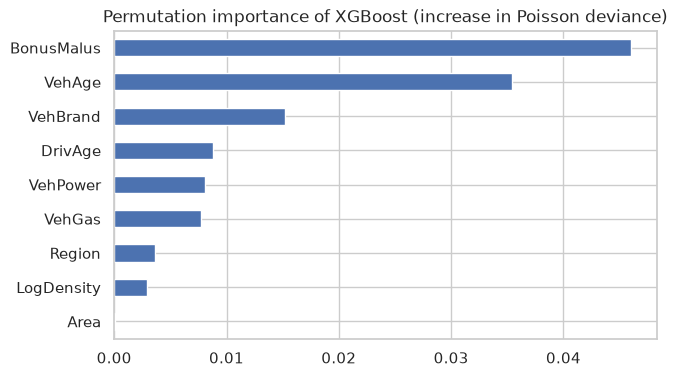

BonusMalus   0.0460
VehAge       0.0354
VehBrand     0.0152
DrivAge      0.0088
VehPower     0.0081
VehGas       0.0078
Region       0.0037
LogDensity   0.0029
Area         0.0000
dtype: float64

In [25]:
perm = permutation_importance(final_xgb, X_test.sample(30000, random_state=1),
                              y_test.loc[X_test.sample(30000, random_state=1).index],
                              scoring="neg_mean_poisson_deviance", n_repeats=3, random_state=42,
                              sample_weight=w_test.loc[X_test.sample(30000, random_state=1).index])
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(7, 4), title="Permutation importance of XGBoost (increase in Poisson deviance)")
plt.show()
imp.sort_values(ascending=False)

The final model agrees with the EDA: **BonusMalus** and **vehicle age** matter most, followed by
brand and driver age. Area adds nothing once `LogDensity` is present (it is a binned version of it).

## 8. Save the selected hyper-parameters

`train.py` reads this file, refits XGBoost on train + validation and saves `models/model.bin`.

In [26]:
Path("models").mkdir(exist_ok=True)
Path("models/best_params.json").write_text(json.dumps(xgb_params, indent=2))
test_table.to_csv("models/test_metrics.csv")
xgb_params

{'max_depth': 8,
 'min_child_weight': 10,
 'learning_rate': 0.05,
 'subsample': 0.8,
 'colsample_bytree': 0.8,
 'n_estimators': 430}